In [ ]:

# Research Papers - Expert System

import pandas as pd
import re

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)


# Question 1.1: Load and clean the data

df = pd.read_json("research_abstracts.json")

print("Dataset shape:", df.shape)
print(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nClass distribution:")
print(df["Label"].value_counts())

print("\nDuplicate abstracts:", df["Abstract"].duplicated().sum())

# Remove records without an abstract or label
df = df.dropna(subset=["Abstract", "Label"]).copy()

# Remove duplicate abstracts
df = df.drop_duplicates(subset=["Abstract"]).copy()


# Clean the text in each abstract
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"<[^>]+>", " ", text)
    text = re.sub(r"\S+@\S+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)

    words = text.split()
    words = [
        word for word in words
        if word not in ENGLISH_STOP_WORDS and len(word) > 1
    ]

    return " ".join(words)


df["Clean_Abstract"] = df["Abstract"].apply(clean_text)

# Remove abstracts that are empty after cleaning
df = df[df["Clean_Abstract"].str.strip() != ""].copy()

print("\nDataset after cleaning:", df.shape)
print(df[["Clean_Abstract", "Label"]].head())


# Question 1.2: Select the features

# The cleaned abstract is the input.
# The label is what the model must predict.
# DOI is an identifier, so it is not used as a feature.

X = df["Clean_Abstract"]
y = df["Label"]

print("\nInput feature: Clean_Abstract")
print("Target variable: Label")
print("\nLabels:")
print(y.value_counts())


# Question 1.3: Build and test a baseline model

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining records:", len(X_train))
print("Testing records:", len(X_test))


# Convert text into numerical features and train the model
model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95
        )
    ),
    (
        "classifier",
        LogisticRegression(max_iter=1000, random_state=42)
    )
])

model.fit(X_train, y_train)


# Make predictions on both datasets
train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)


# Check model performance
train_accuracy = accuracy_score(y_train, train_predictions)
test_accuracy = accuracy_score(y_test, test_predictions)

print("\nTraining accuracy:", round(train_accuracy * 100, 2), "%")
print("Testing accuracy:", round(test_accuracy * 100, 2), "%")

print(
    "Accuracy difference:",
    round((train_accuracy - test_accuracy) * 100, 2),
    "percentage points"
)


# Display the F1 scores
print("\nMacro F1-score:",
      round(f1_score(y_test, test_predictions,
                     average="macro", zero_division=0), 4))

print("Weighted F1-score:",
      round(f1_score(y_test, test_predictions,
                     average="weighted", zero_division=0), 4))


# Show performance for each class
print("\nClassification report:")
print(classification_report(
    y_test,
    test_predictions,
    zero_division=0
))


# Show the confusion matrix
labels = sorted(y.unique())

print("Class order:", labels)
print("Confusion matrix:")
print(confusion_matrix(
    y_test,
    test_predictions,
    labels=labels
))


# Summary of the results
print("\nModel evaluation:")

if train_accuracy - test_accuracy > 0.10:
    print("The model may be overfitting the training data.")
else:
    print("The training and testing accuracies are reasonably close.")

print(
    "The classification report should also be checked because "
    "the dataset contains more classical papers than AI papers."
)


In [ ]:

# Model evaluation

print("\nModel evaluation:")

print("The model achieved a training accuracy of",
      round(train_accuracy * 100, 2), "%")

print("The model achieved a testing accuracy of",
      round(test_accuracy * 100, 2), "%")

print("The difference between training and testing accuracy is",
      round((train_accuracy - test_accuracy) * 100, 2),
      "percentage points.")

if train_accuracy - test_accuracy > 0.10:
    print("The model may be overfitting the training data.")
else:
    print("The training and testing accuracies are reasonably close.")

print("\nConfusion matrix interpretation:")
print("The model correctly classified 10 AI research papers.")
print("It incorrectly classified 37 AI research papers as classical.")
print("It incorrectly classified 0 classical research papers as AI.")
print("The model correctly classified 178 classical research papers.")

print("\nConclusion:")
print("The model performs well when identifying classical research papers,")
print("but struggles to identify AI research papers.")
print("Although the testing accuracy is 83.56%, the model needs to")
print("improve its ability to recognise AI research papers.")
print("The difference in the number of AI and classical papers may")
print("contribute to this result.")


In [ ]:
# Question 2.1: Train and compare four machine learning models

from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
import pandas as pd


# Create the four models

models = {
    "Multinomial Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    )
}


# Train and evaluate each model

results = []
trained_models = {}

for name, classifier in models.items():

    model = Pipeline([
        ("tfidf", TfidfVectorizer(
            max_features=5000,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95
        )),
        ("classifier", classifier)
    ])

    # Train the model
    model.fit(X_train, y_train)

    # Make predictions
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    # Calculate performance metrics
    train_accuracy = accuracy_score(
        y_train, train_predictions
    )

    test_accuracy = accuracy_score(
        y_test, test_predictions
    )

    macro_f1 = f1_score(
        y_test, test_predictions,
        average="macro"
    )

    ai_recall = recall_score(
        y_test, test_predictions,
        pos_label="ai",
        zero_division=0
    )

    # Save the results
    results.append({
        "Model": name,
        "Training Accuracy (%)": round(
            train_accuracy * 100, 2
        ),
        "Testing Accuracy (%)": round(
            test_accuracy * 100, 2
        ),
        "Macro F1-score": round(macro_f1, 4),
        "AI Recall (%)": round(
            ai_recall * 100, 2
        )
    })

    trained_models[name] = model


# Display the comparison table

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="Macro F1-score",
    ascending=False
)

print("Model Performance Comparison")
print(results_df.to_string(index=False))


# Identify the best model based on macro F1-score

best_model_name = results_df.iloc[0]["Model"]

print("\nBest model based on macro F1-score:")
print(best_model_name)

In [ ]:
# Question 2.2: Improve performance using hyperparameter tuning

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, recall_score


# Create the Random Forest pipeline

rf_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95
    )),
    ("classifier", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])


# Define the parameter combinations to test

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [None, 20],
    "classifier__min_samples_split": [2, 5],
    "classifier__min_samples_leaf": [1, 2]
}


# Search for the best combination of parameters

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=3,
    n_jobs=-1,
    verbose=1
)


# Train and tune the model

grid_search.fit(X_train, y_train)


# Select the best model

tuned_model = grid_search.best_estimator_


# Make predictions on the test data

tuned_predictions = tuned_model.predict(X_test)


# Evaluate the tuned model

tuned_accuracy = accuracy_score(
    y_test, tuned_predictions
)

tuned_f1 = f1_score(
    y_test,
    tuned_predictions,
    average="macro"
)

tuned_ai_recall = recall_score(
    y_test,
    tuned_predictions,
    pos_label="ai",
    zero_division=0
)


# Display the results

print("\nHyperparameter Tuning Results")

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation macro F1-score:",
      round(grid_search.best_score_, 4))

print("Testing accuracy:",
      round(tuned_accuracy * 100, 2), "%")

print("Testing macro F1-score:",
      round(tuned_f1, 4))

print("AI recall:",
      round(tuned_ai_recall * 100, 2), "%")


# Compare the tuned model with the original Random Forest

print("\nOriginal Random Forest vs Tuned Random Forest")

print("Original testing accuracy:",
      round(original_accuracy * 100, 2), "%")

print("Tuned testing accuracy:",
      round(tuned_accuracy * 100, 2), "%")

print("Original macro F1-score:",
      round(original_f1, 4))

print("Tuned macro F1-score:",
      round(tuned_f1, 4))

print("Original AI recall:",
      round(original_ai_recall * 100, 2), "%")

print("Tuned AI recall:",
      round(tuned_ai_recall * 100, 2), "%")

In [ ]:
# Save the tuned model for deployment

import joblib

joblib.dump(tuned_model, "research_abstract_classifier.pkl")

print("Tuned model saved successfully.")

In [ ]:

%%writefile app.py

import streamlit as st
import joblib

# Load the trained model
model = joblib.load("research_abstract_classifier.pkl")

# Set up the web page
st.set_page_config(
    page_title="Research Abstract Classifier",
    page_icon="📚",
    layout="centered"
)

st.title("Research Abstract Classifier")

st.write(
    "Enter a research abstract below to classify it as "
    "AI-related or classical research."
)

# Text input area
abstract = st.text_area(
    "Research Abstract",
    placeholder="Paste the research abstract here...",
    height=250
)

# Classify button
if st.button("Classify Abstract"):

    if abstract.strip() == "":
        st.warning("Please enter a research abstract first.")

    else:
        # Predict the category
        prediction = model.predict([abstract])[0]

        st.subheader("Classification Result")

        if prediction == "ai":
            st.success("This abstract is classified as AI-related research.")
        else:
            st.success("This abstract is classified as classical research.")

        st.write("Predicted category:", prediction)


In [ ]:
!python3 -m streamlit run app.py

In [ ]:
import os

print("Current folder:", os.getcwd())
print("App file exists:", os.path.exists("app.py"))
print("Model file exists:", os.path.exists("research_abstract_classifier.pkl"))


In [ ]:
!python3 -m streamlit run app.py --server.headless true

In [1]:
#QUESTION 3.1 

import pandas as pd
import glob
import os

# Find the research article text files
files = sorted(glob.glob("research_*.txt"))

# Store the articles
articles = []

for file in files:
    with open(file, "r", encoding="utf-8") as f:
        content = f.read()

    articles.append({
        "Article": os.path.basename(file),
        "Content": content
    })

# Create the DataFrame
research_df = pd.DataFrame(articles)

# Display the results
print("Number of articles:", len(research_df))
display(research_df[["Article", "Content"]])


Number of articles: 5


,Article,Content
0,research_1.txt,The purposes of this article are to position m...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit..."
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...


In [3]:
#Question 3.2
import re
import nltk
from nltk.corpus import stopwords

# Download English stopwords
nltk.download("stopwords", quiet=True)

stop_words = set(stopwords.words("english"))

def clean_text(text):
    # Convert text to lowercase
    text = text.lower()

    # Remove URLs
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", " ", text)

    # Remove numbers and special characters
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra whitespace
    text = re.sub(r"\s+", " ", text).strip()

    # Remove common English stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

# Apply cleaning to every article
research_df["Cleaned_Content"] = (
    research_df["Content"].apply(clean_text)
)

# Compare the original and cleaned content
display(
    research_df[
        ["Article", "Content", "Cleaned_Content"]
    ]
)

print("Preprocessing completed.")


,Article,Content,Cleaned_Content
0,research_1.txt,The purposes of this article are to position m...,purposes article position mixed methods resear...
1,research_2.txt,"Now I see it, now I don’t:\nresearcher’s posit...",see researcher position reflexivity qualitativ...
2,research_3.txt,DEVELOPMENTAL RESEARCH: STUDIES OF\nINSTRUCTIO...,developmental research studies instructional d...
3,research_4.txt,Abstract\nCronbach’s alpha is a statistic comm...,abstract cronbach alpha statistic commonly quo...
4,research_5.txt,Denzin’s Paradigm Shift: Revisiting Triangulat...,denzin paradigm shift revisiting triangulation...


Preprocessing completed.


Summary of the First Article:
Basic agreement has been
reached on each of the following issues: (a) the relativity of the
“light of reason” (i.e., what appears reasonable can vary across persons); (b) theory-laden perception or the theory-ladenness of facts
(i.e., what we notice and observe is affected by our background
knowledge, theories, and experiences; in short, observation is not
a perfect and direct window into “reality”); (c) underdetermination of theory by evidence (i.e., it is possible for more than
one theory to fit a single set of empirical data); (d) the DuhemQuine thesis or idea of auxiliary assumptions (i.e., a hypothesis
cannot be fully tested in isolation because to make the test we
also must make various assumptions; the hypothesis is embedded
in a holistic network of beliefs; and alternative explanations will
continue to exist); (e) the problem of induction (i.e., the recognition that we only obtain probabilistic evidence, not final proof in
empirical research; in sh

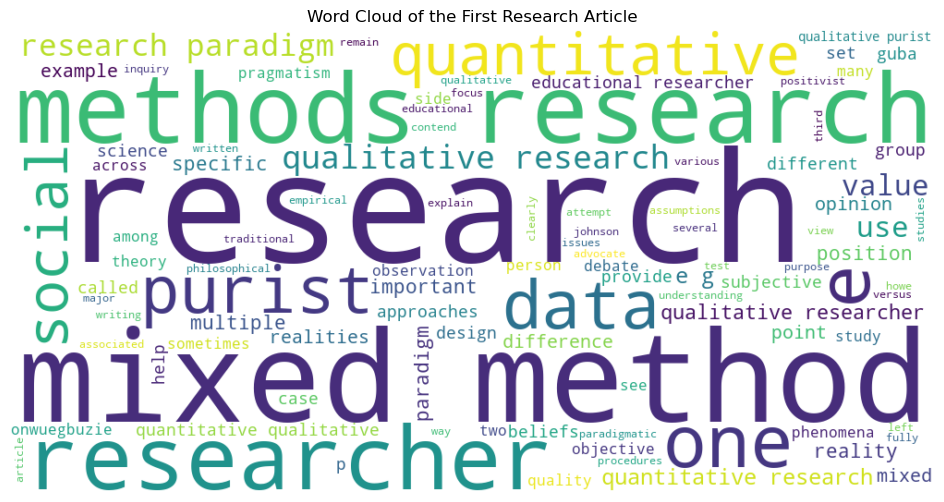

In [5]:
#Question 3.3

import re
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud

# Select the first article
first_article = research_df.iloc[0]["Content"]

# Split the article into sentences
sentences = re.split(r'(?<=[.!?])\s+', first_article.strip())
sentences = [sentence.strip() for sentence in sentences if len(sentence.split()) >= 8]

# Summarise the article using TF-IDF
if len(sentences) < 2:
    print("Not enough sentences to create a summary.")
else:
    vectorizer = TfidfVectorizer(stop_words="english", max_features=3000)
    sentence_matrix = vectorizer.fit_transform(sentences)

    sentence_scores = np.asarray(sentence_matrix.sum(axis=1)).ravel()

    number_of_sentences = min(3, len(sentences))
    top_indices = np.argsort(sentence_scores)[-number_of_sentences:]
    top_indices = sorted(top_indices)

    summary = " ".join(sentences[i] for i in top_indices)

    print("Summary of the First Article:")
    print(summary)

# Create a word cloud
first_cleaned_article = research_df.iloc[0]["Cleaned_Content"]

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white",
    max_words=100
).generate(first_cleaned_article)

plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of the First Research Article")
plt.show()


Topic 1:
data, triangulation, research, study, qualitative, methods, denzin, fusch, design, multiple

Topic 2:
alpha, cronbach, instrument, science, reliability, values, items, education, authors, scales

Topic 3:
research, development, process, developmental, design, instructional, reflexivity, researcher, study, evaluation


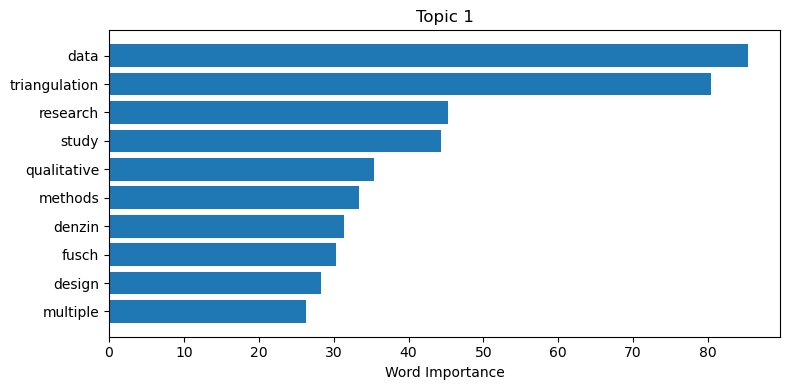

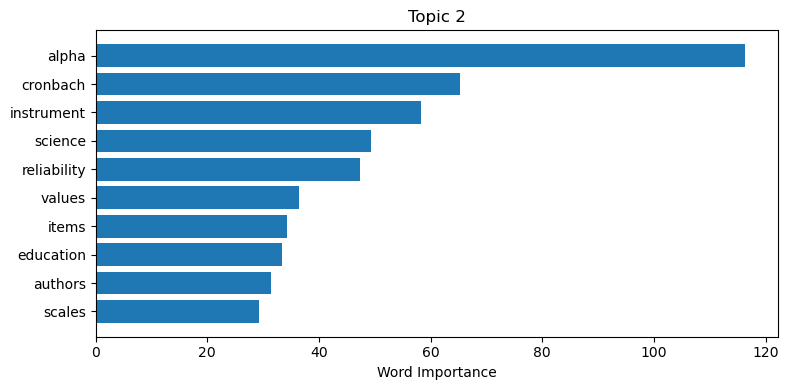

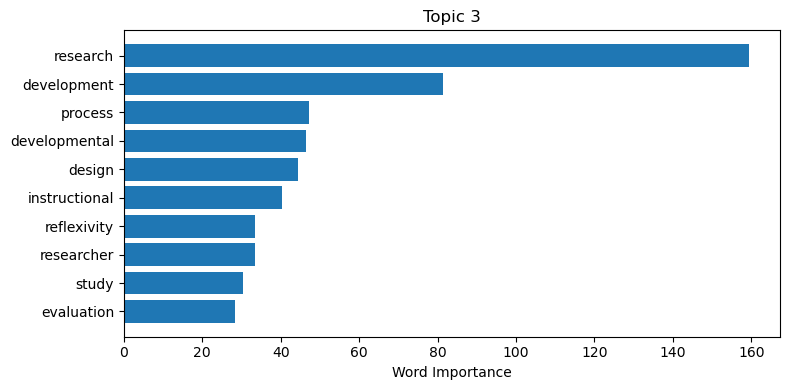

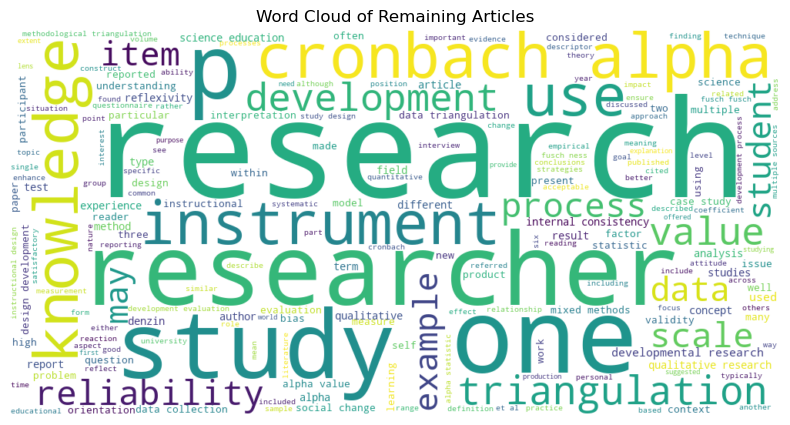

,Article,Topic 1,Topic 2,Topic 3
0,research_2.txt,0.000318,0.000290,0.999392
1,research_3.txt,0.000179,0.000182,0.999639
2,research_4.txt,0.000117,0.999764,0.000118
3,research_5.txt,0.999663,0.000168,0.000169


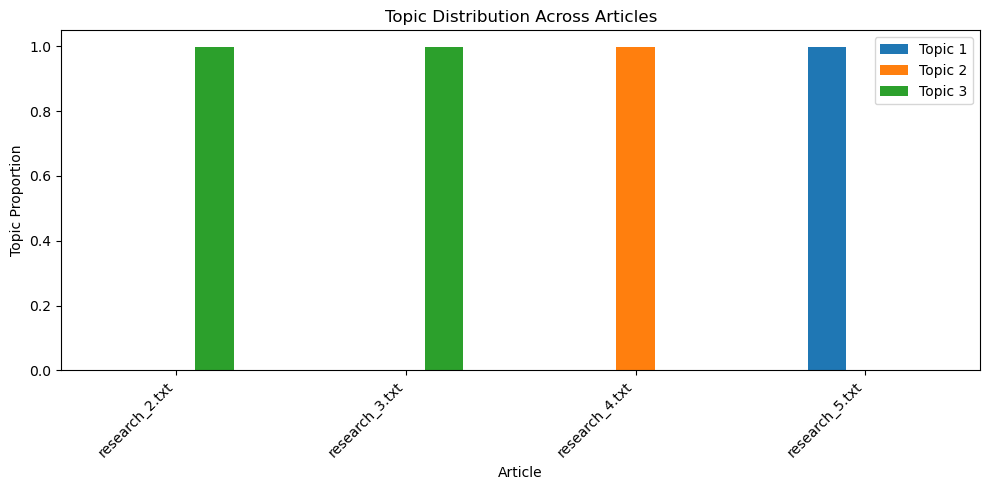

In [7]:
#Question 3.4

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from wordcloud import WordCloud

# Select the remaining articles
remaining_articles = research_df.iloc[1:].copy()
texts = remaining_articles["Cleaned_Content"].fillna("")

# Remove empty articles
valid = texts.str.strip() != ""
texts = texts[valid]
article_names = remaining_articles.loc[valid, "Article"]

# Convert text into word counts
vectorizer = CountVectorizer(stop_words="english")
word_counts = vectorizer.fit_transform(texts)

# Apply LDA topic modelling
lda = LatentDirichletAllocation(
    n_components=3,
    random_state=42
)
lda.fit(word_counts)

# Display the main words for each topic
words = vectorizer.get_feature_names_out()

for i, topic in enumerate(lda.components_):
    top_words = topic.argsort()[-10:][::-1]
    print(f"\nTopic {i + 1}:")
    print(", ".join(words[top_words]))

# Visualise the main words in each topic
for i, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[-10:][::-1]

    plt.figure(figsize=(8, 4))
    plt.barh(words[top_indices][::-1], topic[top_indices][::-1])
    plt.title(f"Topic {i + 1}")
    plt.xlabel("Word Importance")
    plt.tight_layout()
    plt.show()

# Create a word cloud for the remaining articles
combined_text = " ".join(texts)

wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(combined_text)

plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Word Cloud of Remaining Articles")
plt.show()

# Show the topic distribution for each article
distributions = lda.transform(word_counts)

topic_df = pd.DataFrame(
    distributions,
    columns=[f"Topic {i + 1}" for i in range(3)]
)

topic_df.insert(0, "Article", article_names.values)
display(topic_df)

# Visualise the topic distribution
topic_df.set_index("Article").plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Topic Distribution Across Articles")
plt.ylabel("Topic Proportion")
plt.xlabel("Article")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()



Topic 1:
methods, mixed, researchers, quantitative, purists, paradigm, reality, paradigms, educational, guba

Topic 2:
development, developmental, design, instructional, evaluation, type, models, product, specific, learning

Topic 3:
alpha, triangulation, cronbach, instrument, researcher, reliability, science, methods, items, education


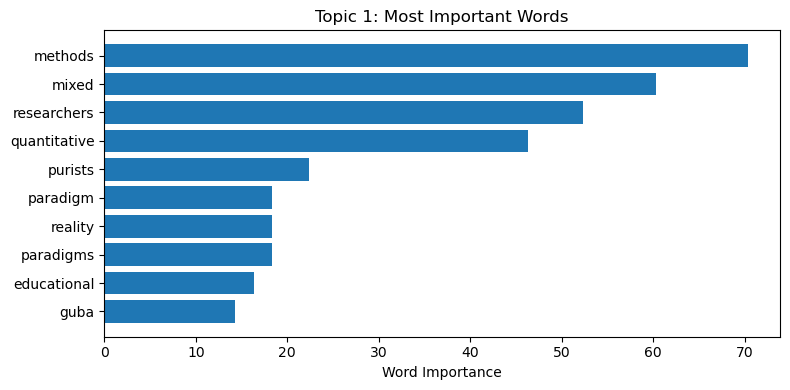

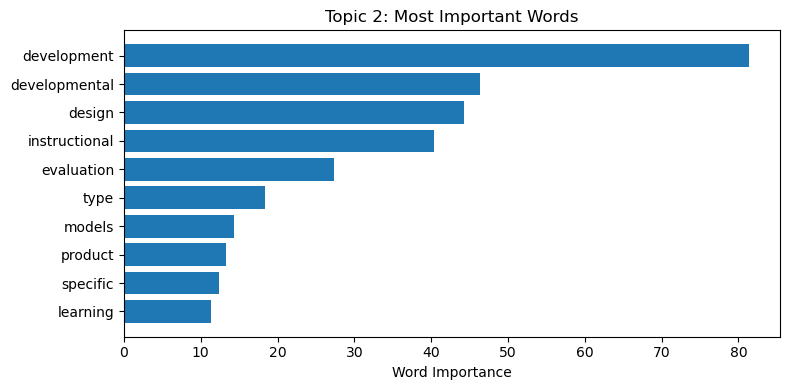

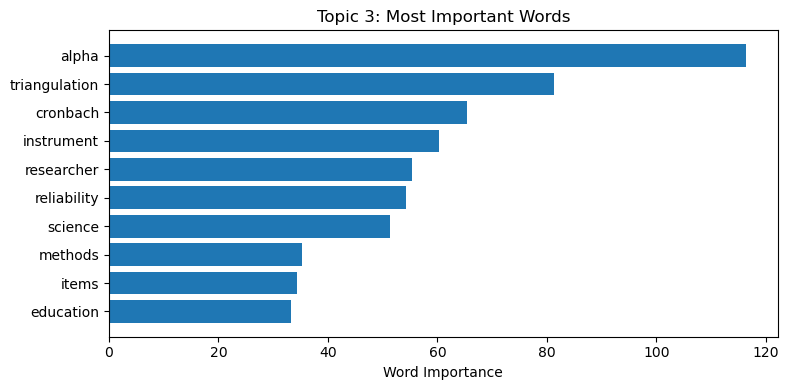

,Article,Topic 1,Topic 2,Topic 3
0,research_1.txt,0.999720,0.000139,0.000141
1,research_2.txt,0.000348,0.000342,0.999310
2,research_3.txt,0.000215,0.999571,0.000214
3,research_4.txt,0.000130,0.000132,0.999738
4,research_5.txt,0.000228,0.000206,0.999566


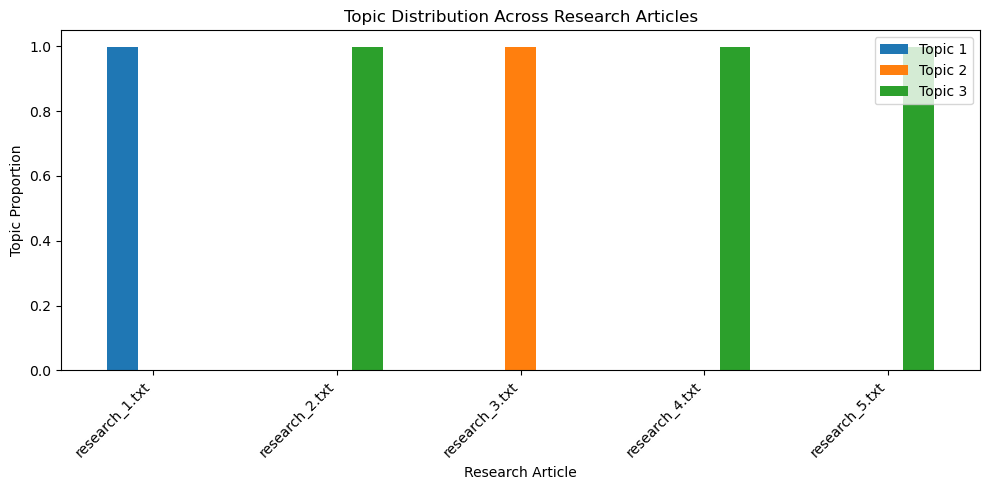

In [9]:
#Question 4.1

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

# Prepare the research articles
texts = research_df["Cleaned_Content"].fillna("")
texts = texts[texts.str.strip() != ""]

# Convert the text into word counts
vectorizer = CountVectorizer(stop_words="english", max_df=0.95)
word_counts = vectorizer.fit_transform(texts)

# Apply LDA to identify three topics
lda = LatentDirichletAllocation(n_components=3, random_state=42)
lda.fit(word_counts)

# Display the main words for each topic
words = vectorizer.get_feature_names_out()

for i, topic in enumerate(lda.components_):
    top_words = topic.argsort()[-10:][::-1]
    print(f"\nTopic {i + 1}:")
    print(", ".join(words[top_words]))

# Visualise the main words in each topic
for i, topic in enumerate(lda.components_):
    top_indices = topic.argsort()[-10:]

    plt.figure(figsize=(8, 4))
    plt.barh(words[top_indices], topic[top_indices])
    plt.title(f"Topic {i + 1}: Most Important Words")
    plt.xlabel("Word Importance")
    plt.tight_layout()
    plt.show()

# Calculate the topic distribution for each article
topic_distribution = lda.transform(word_counts)

topic_df = pd.DataFrame(
    topic_distribution,
    columns=["Topic 1", "Topic 2", "Topic 3"]
)

topic_df.insert(0, "Article", research_df.loc[texts.index, "Article"].values)

display(topic_df)

# Visualise the topic distribution across articles
topic_df.set_index("Article")[["Topic 1", "Topic 2", "Topic 3"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Topic Distribution Across Research Articles")
plt.xlabel("Research Article")
plt.ylabel("Topic Proportion")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [11]:
#Question 4.3
%pip install pyLDAvis

Note: you may need to restart the kernel to use updated packages.


In [13]:
import pyLDAvis
import pyLDAvis.lda_model

# Create the interactive topic map
vis = pyLDAvis.lda_model.prepare(
    lda,
    word_counts,
    vectorizer,
    mds="pcoa"
)

pyLDAvis.display(vis)